In [150]:
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
# if not os.environ.get("DISPLAY"):
#     matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.path import Path as MplPath
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable

import cmocean
# from tools import *
try:
    import geopandas as gpd
except ImportError:
    gpd = None

import math as ma

In [151]:
SADCP_AVG = "10min"          # SADCP time averaging (~3 km at 10 kn)
USE_DETIDED = True           # use UVEL_ADCP_CORTIDE / VVEL_ADCP_CORTIDE when present
Z_SPLIT = 150.0              # m: OS150 above, OS38 below
ZMAX_SADCP = 1000.0
Z_FILL_GAP = 40.0            # m: fill vertical gaps up to this size (seam between OS150/OS38)
DS_KM = 3.0                  # bin size along a section
R_BIN_KM = 10.0              # radius bin (radial mode)
FIT_CENTER = True            # radial mode: refine the TOEddies center from SADCP
FIT_LAYER = (30.0, 200.0)    # m: layer used to fit the center
FIT_SEARCH_KM = 60.0         # search +- this offset around the TOEddies center
CENTER_SMOOTH_DAYS = 3       # running mean on the daily TOEddies centers
PROFILE_DEPTHS = [50, 100, 200, 400, 700]
R_KM = 6371.0

In [175]:
def _find(ds, names, required=True):
    for n in names:
        if n in ds.variables:
            return n
    low = {k.lower(): k for k in ds.variables}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    if required:
        raise KeyError(f"None of {names} in {list(ds.variables)}")
    return None

def load_track(name):
    p = DIR_TRACKS
    f = next(iter(sorted(DIR_TRACKS.rglob(f"tracked_eddy_{name}.csv"))), None)
    if f is None:
        raise FileNotFoundError(f"tracked_eddy_{name}.csv not found under {DIR_TRACKS}")
    return pd.read_csv(f, parse_dates=["date"])


def center_at(tr, times):
    """TOEddies center at given times: daily centers at 12:00, running mean, linear interp."""
    t = tr.date + pd.Timedelta(hours=12)
    lon = tr.lon.rolling(CENTER_SMOOTH_DAYS, center=True, min_periods=1).mean().values
    lat = tr.lat.rolling(CENTER_SMOOTH_DAYS, center=True, min_periods=1).mean().values
    tq = pd.to_datetime(times).values.astype("datetime64[s]").astype(float)
    tt = t.values.astype("datetime64[s]").astype(float)
    return np.interp(tq, tt, lon), np.interp(tq, tt, lat)


def rmax_at(tr, t0, t1):
    m = (tr.date >= pd.Timestamp(t0).normalize()) & (tr.date <= pd.Timestamp(t1))
    return float(tr.loc[m, "r_maxspeed_km"].mean())


def eddy_color(cfg):
    return "tab:red" if cfg["eddy_type"] == 1 else "tab:blue"


_SADCP_CACHE = {}

def load_sadcp_raw(path):
    """Full-resolution SADCP as Dataset(time, z) with u, v, lat, lon (QC flag == 1)."""
    if path in _SADCP_CACHE:
        return _SADCP_CACHE[path]
    ds = xr.open_dataset(path)
    tn = _find(ds, ["JULD_ADCP", "TIME", "time", "JULD"])
    zn = _find(ds, ["DEPH", "DEPTH", "depth"])
    un = _find(ds, ["UVEL_ADCP_CORTIDE"], required=False) if USE_DETIDED else None # tide correction
    vn = _find(ds, ["VVEL_ADCP_CORTIDE"], required=False) if USE_DETIDED else None
    if un is None or vn is None:
        un, vn = _find(ds, ["UVEL_ADCP"]), _find(ds, ["VVEL_ADCP"])
    fn = _find(ds, ["CAS_CURRENT_FLAG"], required=False)
    print(f"  {Path(path).name}: using {un}, {vn}")
    tdim = ds[tn].dims[0]
    U = ds[un].squeeze(drop=True)
    zdim = [d for d in U.dims if d != tdim][0]
    u = U.transpose(tdim, zdim).values.astype(float)
    v = ds[vn].squeeze(drop=True).transpose(tdim, zdim).values.astype(float)
    traw = ds[tn].values
    time = (pd.to_datetime(traw) if np.issubdtype(traw.dtype, np.datetime64)
    \
            else pd.Timestamp("1950-01-01") + pd.to_timedelta(traw.astype(float), unit="D"))
    if fn is not None:
        fl = ds[fn].squeeze(drop=True)
        fl = fl.transpose(tdim, zdim).values if zdim in fl.dims else fl.values[:, None]
        good = (fl == 1) if np.issubdtype(fl.dtype, np.number) else \
            np.char.strip(np.char.decode(fl.astype("S"), "ascii", "ignore")) == "1"
        good = np.broadcast_to(good, u.shape)
        u, v = np.where(good, u, np.nan), np.where(good, v, np.nan)
    u[np.abs(u) > 5] = np.nan
    v[np.abs(v) > 5] = np.nan
    zda = ds[zn].squeeze(drop=True)
    z = np.abs(np.nanmedian(zda.transpose(tdim, zdim).values, axis=0) if zda.ndim == 2
               else zda.values).astype(float)
    keepz = np.isfinite(z)
    lat = ds[_find(ds, ["LATITUDE", "lat"])].squeeze(drop=True).values.astype(float)
    lon = ds[_find(ds, ["LONGITUDE", "lon"])].squeeze(drop=True).values.astype(float)
    lat = np.where(np.abs(lat) <= 90, lat, np.nan)
    lon = np.where(np.abs(lon) <= 360, lon, np.nan)
    lon = np.where(lon > 180, lon - 360, lon)
    out = xr.Dataset({"u": (("time", "z"), u[:, keepz]), "v": (("time", "z"), v[:, keepz]),
                      "lat": ("time", lat), "lon": ("time", lon)},
                     coords={"time": np.asarray(time, "datetime64[ns]"), "z": z[keepz]})
    out = out.isel(time=np.asarray(pd.notna(time))).sortby("time").sortby("z")
    out = out.isel(time=~pd.Index(out.time.values).duplicated())
    ds.close()
    _SADCP_CACHE[path] = out
    return out

def sadcp_window(t0, t1):
    """OS150 above Z_SPLIT + OS38 below, averaged over SADCP_AVG, inside [t0, t1].
    Returns a dict of numpy arrays: time, lon, lat, z, u (nt, nz), v (nt, nz)."""
    parts = []
    for inst, f in SADCP_FILES.items():
        if not f.exists():
            print(f"  ! missing {f}")
            continue
        d = load_sadcp_raw(f).sel(time=slice(t0, t1)).resample(time=SADCP_AVG).mean()
        zz = d.z.values
        keep = zz <= Z_SPLIT if inst == "OS150" else (zz > Z_SPLIT) & (zz <= ZMAX_SADCP)
        parts.append(d.isel(z=np.where(keep)[0]))
    if not parts:
        raise FileNotFoundError("no SADCP file found")
    out = parts[0]
    for p in parts[1:]:
        p = p.reindex(time=out.time)
        out = xr.Dataset({"u": xr.concat([out.u, p.u], "z"), "v": xr.concat([out.v, p.v], "z"),
                          "lat": out.lat.fillna(p.lat), "lon": out.lon.fillna(p.lon)})
    out = out.sortby("z")
    ok = np.isfinite(out.lat.values) & np.isfinite(out.lon.values) & np.isfinite(out.u.values).any(1)
    out = out.isel(time=ok)
    return dict(time=out.time.values, lon=out.lon.values, lat=out.lat.values, z=out.z.values,
                u=out.u.values, v=out.v.values)
"""Along-track distance and cross-track (orthogonal) velocity for ship ADCP data."""
import numpy as np
from pyproj import Geod

geod = Geod(ellps="WGS84")


def _unwrap_lon(lon):
    """Make longitudes continuous across the ±180° line (needed before interpolating)."""
    lon = np.asarray(lon, float).copy()
    ok = np.isfinite(lon)
    lon[ok] = np.rad2deg(np.unwrap(np.deg2rad(lon[ok])))
    return lon


def along_track_distance(lon, lat):
    """
    Cumulative geodesic distance along a track, in meters.

    Positions that are NaN get NaN distance, but they don't break the
    cumulative sum: the distance keeps counting from the last valid fix
    to the next one. Stationary fixes simply repeat the same distance.
    """
    lon = np.asarray(lon, float)
    lat = np.asarray(lat, float)
    ok = np.isfinite(lon) & np.isfinite(lat)

    dist = np.full(lon.shape, np.nan)
    idx = np.flatnonzero(ok)
    if idx.size == 0:
        return dist
    _, _, seg = geod.inv(lon[idx[:-1]], lat[idx[:-1]], lon[idx[1:]], lat[idx[1:]])
    dist[idx] = np.concatenate([[0.0], np.cumsum(seg)])
    return dist


def track_heading(lon, lat, x_dist=None, smooth_km=2.0):
    """
    Ship course (degrees clockwise from north) at each fix, measured over
    ±smooth_km/2 of along-track distance rather than between neighbouring fixes.

    Using a distance window instead of np.gradient means the heading stays
    stable while the ship is on station or creeping, and GPS jitter is averaged
    out. Where less than ~smooth_km/4 of track is available around a fix
    (e.g. a long station, or the very start/end), the heading is NaN.
    """
    lon = _unwrap_lon(lon)
    lat = np.asarray(lat, float)
    x = along_track_distance(lon, lat) if x_dist is None else np.asarray(x_dist, float)
    x = x / 1000.0  # km

    ok = np.isfinite(x) & np.isfinite(lon) & np.isfinite(lat)
    heading = np.full(lon.shape, np.nan)
    if ok.sum() < 2:
        return heading

    # np.interp needs strictly increasing x: keep one fix per distinct distance
    xs, first = np.unique(x[ok], return_index=True)
    lons, lats = lon[ok][first], lat[ok][first]
    if xs.size < 2:
        return heading

    half = smooth_km / 2.0
    xa = np.clip(x[ok] - half, xs[0], xs[-1])
    xb = np.clip(x[ok] + half, xs[0], xs[-1])
    lon_a, lat_a = np.interp(xa, xs, lons), np.interp(xa, xs, lats)
    lon_b, lat_b = np.interp(xb, xs, lons), np.interp(xb, xs, lats)

    az, _, d = geod.inv(lon_a, lat_a, lon_b, lat_b)
    az = np.where(d > 250.0 * smooth_km, az, np.nan)  # need >= smooth_km/4 of track
    heading[ok] = az % 360.0
    return heading


def orthogonal_velocity(adcp, x_dist=None, smooth_km=2.0, return_along=False):
    """
    Velocity component perpendicular to the ADCP track (positive = to the LEFT
    of the direction of travel), shape (time, depth).

    Parameters
    ----------
    adcp : xarray.Dataset
        Must contain lon_adcp(time), lat_adcp(time),
        uvel_adcp(time, depth), vvel_adcp(time, depth).
    x_dist : array-like, optional
        Cumulative along-track distance in meters. Computed if not given.
    smooth_km : float
        Length of track used to define the local course (see track_heading).
        Use roughly the scale of the ship's real turns: 1-5 km is typical.
    return_along : bool
        Also return the along-track component (positive = direction of travel).

    Notes
    -----
    The course comes from geodesic azimuths, so the east/north directions are
    correctly scaled (no degrees-of-longitude distortion).
    The sign flips if the ship reverses course: on a track that turns back,
    "left of track" points the other way, so compare sections with care.
    """
    lon = adcp["lon"]
    lat = adcp["lat"]
    tdim = np.shape(adcp["time"])[0]
    u = adcp["u"]
    v = adcp["v"]

    az = np.deg2rad(track_heading(lon, lat, x_dist, smooth_km))

    # unit tangent (east, north) and its 90° anticlockwise rotation (left normal)
    tx, ty = np.sin(az)[:, None], np.cos(az)[:, None]
    nx, ny = -ty, tx

    v_orth = u * nx + v * ny
    if return_along:
        return v_orth, u * tx + v * ty
    return v_orth


def _crossings(lon, lat, x, xy):
    """x where the ship track enters / leaves contour xy, and the inside mask per fix."""
    ok = np.isfinite(lon) & np.isfinite(lat) & np.isfinite(x)
    inside = np.zeros(len(lon), bool)
    if xy is None or not ok.any():
        return np.array([]), inside
    inside[ok] = MplPath(xy).contains_points(np.c_[lon[ok], lat[ok]])
    idx = np.flatnonzero(ok)
    io = inside[idx]
    k = np.flatnonzero(io[1:] != io[:-1])          # change between consecutive valid fixes
    return 0.5 * (x[idx[k]] + x[idx[k + 1]]), inside


def plot_adcp_section(curr_day, adcp_mag, x_dist, title, vmin, vmax, cmap="viridis", cyc=True,
                      eddy=None, x_fix=None, eddy_center_nencioli=None, invert_x=True,
                      savefig=None):
    """
    Velocity section with the TOEddies eddy drawn on it.

    curr_day : dict with z, and lon/lat of every SADCP fix (e.g. `sad`)
    adcp_mag : (nx, nz) field on the x grid `x_dist` [km]
    eddy     : dict from toeddies_eddy() -> center (lon, lat), maxspeed and outer contours
    x_fix    : x [km] of every fix in curr_day, on the SAME axis as x_dist.
               Not needed when x_dist is already one value per fix (Fig 1).
               For the binned section (Fig 2) pass `s - s_c`.

    Drawn: vertical lines where the ship crosses the outer (dashed) and max-speed (solid)
    contours, dash-dot at the ship's closest approach to the TOEddies center, and a strip on
    top showing, fix by fix, when the ship is inside each contour.
    """
    col = "blue" if cyc else "red"
    fig, ax = plt.subplots(figsize=(10, 4.6))
    c = ax.pcolormesh(x_dist, -curr_day["z"], np.asarray(adcp_mag).T, vmin=vmin, vmax=vmax,
                      cmap=cmap, shading="auto")
    handles = []
    div = make_axes_locatable(ax)

    if eddy is not None:
        lon = np.asarray(curr_day["lon"], float)
        lat = np.asarray(curr_day["lat"], float)
        if x_fix is None:
            if len(x_dist) != len(lon):
                raise ValueError("x_dist is not one value per fix: pass x_fix (e.g. s - s_c)")
            x_fix = x_dist
        x_fix = np.asarray(x_fix, float)

        x_oc, in_oc = _crossings(lon, lat, x_fix, eddy.get("outer"))
        x_ms, in_ms = _crossings(lon, lat, x_fix, eddy.get("maxspeed"))
        for xv in x_oc:
            ax.axvline(xv, color=col, ls="--", lw=1.2)
        for xv in x_ms:
            ax.axvline(xv, color=col, ls="-", lw=1.4)

        # closest approach of the ship to the TOEddies center
        clon, clat = eddy["center"]
        dkm = R_KM * np.hypot(np.deg2rad(lon - clon) * np.cos(np.deg2rad(clat)),
                              np.deg2rad(lat - clat))
        j = int(np.nanargmin(np.where(np.isfinite(x_fix), dkm, np.nan)))
        ax.axvline(x_fix[j], color=col, ls="-.", lw=1.4)

        tag = f"{eddy['date']:%d %b}" if "date" in eddy else "TOEddies"
        handles += [
            Line2D([], [], color=col, ls="-", label="max-speed contour"),
            Line2D([], [], color=col, ls="-.",
                   label=f"TOEddies Center (closest approach {dkm[j]:.0f} km)"),
        ]
        print(f"max-speed contour crossed at x = {np.round(x_ms, 1)} km\n"
              f"closest approach to the center: {dkm[j]:.1f} km at x = {x_fix[j]:.1f} km")
    else:
        ax.set_title(title)

        if eddy_center_nencioli is not None:
            print("Plotting Nencioli Center")
            xn = np.atleast_1d(np.asarray(eddy_center_nencioli, float))
            if xn.size == 1:                                    # one center: vertical line
                ax.axvline(xn[0], color="k", ls="-.", lw=1.4)
            else:                                               # one center per depth level
                ax.plot(xn, -np.asarray(curr_day["z"]), color="k", ls="-.", lw=1.4)
        handles.append(Line2D([], [], color="k", ls="-.", label="center (Nencioli)"))
    if invert_x:
        ax.invert_xaxis()           # also inverts the shared strip
    fig.colorbar(c, cax=div.append_axes("right", size="2.5%", pad=0.15)).set_label("Velocity [m/s]")
    if handles:
        ax.legend(handles=handles, loc="lower left", fontsize="small", framealpha=0.85)
    ax.set_xlabel("Distance [km]")
    ax.set_ylabel("Depth [m]")
    ax.set_title(title)
    if savefig is not None:
        fig.savefig(savefig, bbox_inches="tight")
    return fig, ax

def _xy_contour(geom):
    """Outline (lon, lat) of a (Multi)Polygon / LineString, NaNs removed, lon in [-180, 180]."""
    if geom is None or geom.is_empty:
        return None
    if geom.geom_type == "Polygon":
        xy = np.asarray(geom.exterior.coords)
    elif geom.geom_type == "MultiPolygon":
        xy = np.asarray(max(geom.geoms, key=lambda g: g.area).exterior.coords)
    elif geom.geom_type in ("LineString", "LinearRing"):
        xy = np.asarray(geom.coords)
    elif geom.geom_type == "MultiLineString":
        xy = np.asarray(max(geom.geoms, key=lambda g: g.length).coords)
    else:
        return None
    xy = xy[:, :2][np.isfinite(xy[:, :2]).all(axis=1)]
    xy[:, 0] = np.where(xy[:, 0] > 180, xy[:, 0] - 360, xy[:, 0])
    return xy if len(xy) > 2 else None

def toeddies_eddy(date, lon, lat, cyc=True, dirs=None):
    """TOEddies eddy nearest to (lon, lat) on `date`: dict with center (lon, lat),
    maxspeed and outer contours (N x 2 lon/lat arrays), its index in the file and
    the distance [km] from (lon, lat)."""
    import glob
    if gpd is None:
        raise ImportError("geopandas is needed to read the TOEddies files")
    kind = "cyclones" if cyc else "anticyclones"
    d = pd.Timestamp(date)
    dirs = list(DIR_EDDIES.values()) if dirs is None else dirs

    def find(part):
        for folder in dirs:
            for tag in (d.strftime("%Y%m%d"), d.strftime("%Y-%m-%d")):
                for f in sorted(glob.glob(str(Path(folder) / f"*{tag}*"))):
                    name = Path(f).name.lower()
                    if (kind == "anticyclones") != ("anticyclon" in name):
                        continue        # "cyclones" is also inside "anticyclones"
                    if part in name and name.endswith((".geojson", ".json", ".shp")):
                        return gpd.read_file(f)
        return None

    cen = find("centers")
    if cen is None:
        raise FileNotFoundError(f"no TOEddies {kind} centers for {d:%Y-%m-%d}")
    ok = (cen.geometry.notna() & ~cen.geometry.is_empty).values
    clon = np.full(len(cen), np.nan)
    clat = np.full(len(cen), np.nan)
    clon[ok], clat[ok] = cen.geometry[ok].x.values, cen.geometry[ok].y.values
    clon = np.where(clon > 180, clon - 360, clon)
    dist = R_KM * np.hypot(np.deg2rad(clon - lon) * np.cos(np.deg2rad(lat)),
                           np.deg2rad(clat - lat))
    i = int(np.nanargmin(dist))

    def contour(part):
        g = find(part)
        if g is None or len(g) == 0:
            return None
        if len(g) == len(cen):                      # same order as the centers file
            xy = _xy_contour(g.geometry.iloc[i])
            if xy is not None:
                return xy
        p = cen.geometry.iloc[i]
        for geom in g.geometry:                     # otherwise: the contour holding the center
            if geom is not None and not geom.is_empty and geom.geom_type.endswith("Polygon") \
                    and geom.contains(p):
                return _xy_contour(geom)
        return None

    out = dict(center=(clon[i], clat[i]), maxspeed=contour("maxspeed"),
               outer=contour("outcontour"), index=i, dist_km=float(dist[i]),
               date=d.normalize())
    print(f"TOEddies {kind[:-1]} #{i} on {d:%Y-%m-%d}: center {clon[i]:.3f}, {clat[i]:.3f} "
          f"({dist[i]:.1f} km from the requested point)")
    return out

def to_xy(lon, lat, lon0, lat0):
    """Local tangent plane, km."""
    x = np.deg2rad(np.asarray(lon, float) - lon0) * R_KM * np.cos(np.deg2rad(lat0))
    y = np.deg2rad(np.asarray(lat, float) - lat0) * R_KM
    return x, y
def fit_line(x, y):
    """Principal axis of the points: origin, along unit vector (direction of travel),
    normal unit vector (LEFT of travel)."""
    ok = np.isfinite(x) & np.isfinite(y)
    xm, ym = x[ok].mean(), y[ok].mean()
    w, vec = np.linalg.eigh(np.cov(np.vstack([x[ok] - xm, y[ok] - ym])))
    es = vec[:, np.argmax(w)]
    xi, yi = x[ok][[0, -1]], y[ok][[0, -1]]
    if (xi[1] - xi[0]) * es[0] + (yi[1] - yi[0]) * es[1] < 0:
        es = -es
    return np.array([xm, ym]), es, np.array([-es[1], es[0]])

def bin_columns(coord, vals, edges, nmin=1):
    """Mean of vals (n, nz) in bins of coord. Returns centers, (nbins, nz) mean, counts."""
    idx = np.digitize(coord, edges) - 1
    out = np.full((len(edges) - 1, vals.shape[1]), np.nan)
    cnt = np.zeros(len(edges) - 1, int)
    for b in range(len(edges) - 1):
        m = idx == b
        cnt[b] = m.sum()
        if cnt[b] >= nmin:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                out[b] = np.nanmean(vals[m], axis=0)
    return 0.5 * (edges[:-1] + edges[1:]), out, cnt
def fill_z_gaps(V, z, max_gap=Z_FILL_GAP):
    """Linear interpolation in depth across interior gaps no thicker than max_gap."""
    V = V.copy()
    for i in range(V.shape[0]):
        ok = np.isfinite(V[i])
        if ok.sum() < 2:
            continue
        zk = z[ok]
        bad = np.where(~ok & (z > zk.min()) & (z < zk.max()))[0]
        if not len(bad):
            continue
        j = np.searchsorted(zk, z[bad])
        small = (zk[j] - zk[j - 1]) <= max_gap
        V[i, bad[small]] = np.interp(z[bad[small]], zk, V[i, ok])
    return V


In [176]:
EDDIES = {
    "CE18": dict(name="CE17_20260512", eddy_type=-1, mode="section",
                 t0="2026-07-16T06:00", t1="2026-07-17T16:00"),
    "AE11": dict(name="AE11_20260514", eddy_type=1, mode="radial",
                 t0="2026-07-01T00:00", t1="2026-07-11T00:00", r_limit_km=220),
}
curr_eddy = EDDIES["CE18"]

In [177]:
BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
DIR_TRACKS = BASE / "eddies" / curr_eddy["name"]
OUT_DIR = BASE / "figures"

In [178]:
tr = load_track(curr_eddy["name"])
t0, t1 = curr_eddy["t0"], curr_eddy["t1"]
tmid = pd.Timestamp(t0) + (pd.Timestamp(t1) - pd.Timestamp(t0)) / 2

# get the eddy center in the interval
clon, clat = (float(a[0]) for a in center_at(tr, [tmid])) 

# get the mean eddy maximum speed radius
rmax = rmax_at(tr, t0, t1)

col = eddy_color(curr_eddy)

sad = sadcp_window(t0, t1)


  WHIRLS_NB150_TOT_osite.nc: using UVEL_ADCP_CORTIDE, VVEL_ADCP_CORTIDE
  WHIRLS_BB38_TOT_osite.nc: using UVEL_ADCP_CORTIDE, VVEL_ADCP_CORTIDE


In [179]:
x_dist = along_track_distance(sad["lon"], sad["lat"])
ortho_vel = orthogonal_velocity(sad)

TOEddies cyclone #24 on 2026-07-16: center 12.812, -37.062 (7.0 km from the requested point)
max-speed contour crossed at x = [ 51.1 260.3] km
closest approach to the center: 12.5 km at x = 208.3 km


(<Figure size 1000x460 with 2 Axes>,
 <Axes: title={'center': 'Velocity Perpendicular to Ship'}, xlabel='Distance [km]', ylabel='Depth [m]'>)

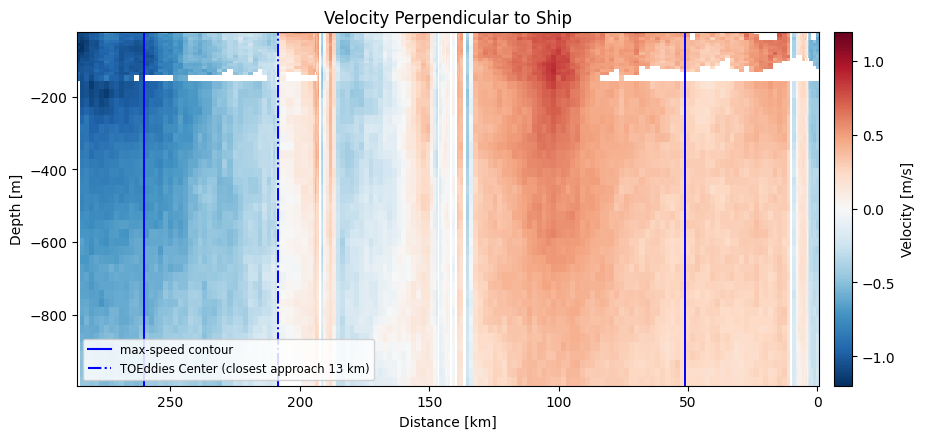

In [180]:
# TOEddies eddy (center, max-speed and outer contours) on the middle day of the section
cyc = curr_eddy["eddy_type"] == -1
edd = toeddies_eddy(tmid, clon, clat, cyc=cyc)

plot_adcp_section(sad, ortho_vel, x_dist/1000, "Velocity Perpendicular to Ship", -1.2, 1.2,
                  cmap="RdBu_r", cyc=cyc, eddy=edd)

In [181]:
lon0, lat0 = float(np.nanmean(sad["lon"])), float(np.nanmean(sad["lat"]))
xs, ys = to_xy(sad["lon"], sad["lat"], lon0, lat0)
origin, es, en = fit_line(xs, ys)
proj_s = lambda x, y: (x - origin[0]) * es[0] + (y - origin[1]) * es[1]
proj_n = lambda x, y: (x - origin[0]) * en[0] + (y - origin[1]) * en[1]
cx, cy = to_xy(clon, clat, lon0, lat0)
s_c, d_c = float(proj_s(cx, cy)), float(proj_n(cx, cy))
heading = (np.degrees(np.arctan2(es[0], es[1])) + 360) % 360

s = proj_s(xs, ys)
vn = sad["u"] * en[0] + sad["v"] * en[1]
xg, V, _ = bin_columns(s, vn, np.arange(np.floor(s.min()), np.ceil(s.max()) + DS_KM, DS_KM))
z = sad["z"]
V = fill_z_gaps(V, z)
x = xg - s_c


In [182]:
# =============================================================================
# Eddy center with the Nencioli et al. (2008) method, in the section frame
# =============================================================================
# For every candidate center on a grid, each SADCP velocity is split into a radial and a
# tangential component about that candidate. The center is where the RMS of the radial
# velocity is smallest (flow is purely azimuthal around the true center). The mean
# tangential velocity is kept as a check (largest |.| at the center).
# Everything is done in the section frame of the previous cell (km, s along / n across the
# best-fit line), so the result lands directly on the Fig 2 x-axis: x = s_center - s_c.
NEN_DS_KM = 1.0        # candidate grid step along the section [km]
NEN_DN_KM = 2.0        # candidate grid step across the section [km]
NEN_MIN_FRAC = 0.5     # skip depth levels with fewer valid fixes than this fraction


def nencioli_center(ps, pn, ua, un, s_grid, n_grid):
    """
    ps, pn : position of each fix along / across the section [km]
    ua, un : velocity of each fix along / across the section [m/s]
    Returns rms_radial, mean_tangential (len(n_grid), len(s_grid)) and the best
    (s, n) = minimum of rms_radial. Tangential > 0 = anticlockwise about the candidate.
    """
    ok = np.isfinite(ps) & np.isfinite(pn) & np.isfinite(ua) & np.isfinite(un)
    ps, pn, ua, un = ps[ok], pn[ok], ua[ok], un[ok]
    S, N = np.meshgrid(s_grid, n_grid)                      # (nN, nS)
    dx = ps[None, None, :] - S[..., None]                   # candidate -> fix
    dy = pn[None, None, :] - N[..., None]
    r = np.hypot(dx, dy)
    r = np.where(r > 0, r, np.nan)
    cos, sin = dx / r, dy / r
    radial = ua * cos + un * sin
    tangential = -ua * sin + un * cos
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        rms = np.sqrt(np.nanmean(radial ** 2, axis=-1))
        mtg = np.nanmean(tangential, axis=-1)
    k = np.unravel_index(np.nanargmin(rms), rms.shape)
    best = (S[k], N[k])
    on_edge = k[0] in (0, len(n_grid) - 1) or k[1] in (0, len(s_grid) - 1)
    return rms, mtg, best, on_edge


def section_to_lonlat(sv, nv):
    """Section coordinates [km] -> lon, lat (inverse of to_xy + projection)."""
    px = origin[0] + es[0] * sv + en[0] * nv
    py = origin[1] + es[1] * sv + en[1] * nv
    lat = lat0 + np.rad2deg(py / R_KM)
    lon = lon0 + np.rad2deg(px / (R_KM * np.cos(np.deg2rad(lat0))))
    return lon, lat


# fix positions and velocity components in the section frame (raw 10-min fixes, not binned)
ps = s                                       # along the section [km]
pn = proj_n(xs, ys)                          # across the section [km], + = left of travel
ua = sad["u"] * es[0] + sad["v"] * es[1]     # along-section velocity
un = sad["u"] * en[0] + sad["v"] * en[1]     # across-section velocity (= what Fig 2 shows)

# candidate grid: the whole section along, +- FIT_SEARCH_KM across around the TOEddies center
s_grid = np.arange(np.nanmin(s), np.nanmax(s) + NEN_DS_KM, NEN_DS_KM)
n_grid = np.arange(d_c - FIT_SEARCH_KM, d_c + FIT_SEARCH_KM + NEN_DN_KM, NEN_DN_KM)

# 1) one robust center from the layer mean (FIT_LAYER)
lay = (z >= FIT_LAYER[0]) & (z <= FIT_LAYER[1])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    ua_l, un_l = np.nanmean(ua[:, lay], axis=1), np.nanmean(un[:, lay], axis=1)
rms_l, mtg_l, (s_nen, n_nen), edge_l = nencioli_center(ps, pn, ua_l, un_l, s_grid, n_grid)
lon_nen, lat_nen = section_to_lonlat(s_nen, n_nen)
x_nen = s_nen - s_c                          # on the Fig 2 x-axis
print(f"Nencioli center ({FIT_LAYER[0]:.0f}-{FIT_LAYER[1]:.0f} m): {lon_nen:.3f}E {lat_nen:.3f}N | "
      f"x = {x_nen:.1f} km on the section, {n_nen:.1f} km across the line "
      f"(TOEddies: x = 0, {d_c:.1f} km across)" + ("  ! on the grid edge" if edge_l else ""))

# 2) center at every depth level
nz = len(z)
cen = {k: np.full(nz, np.nan) for k in ("s", "n", "rms", "mtg")}
cen["edge"] = np.zeros(nz, bool)
nfix = np.isfinite(ps).sum()
for i in range(nz):
    if np.isfinite(un[:, i]).sum() < NEN_MIN_FRAC * nfix:
        continue
    rms_i, mtg_i, (sb, nb), edge = nencioli_center(ps, pn, ua[:, i], un[:, i], s_grid, n_grid)
    j = (np.argmin(np.abs(n_grid - nb)), np.argmin(np.abs(s_grid - sb)))
    cen["s"][i], cen["n"][i], cen["edge"][i] = sb, nb, edge
    cen["rms"][i], cen["mtg"][i] = rms_i[j], mtg_i[j]
cen["x"] = cen["s"] - s_c                                  # Fig 2 x-axis
cen["lon"], cen["lat"] = section_to_lonlat(cen["s"], cen["n"])
# Fig 1 x-axis: distance travelled at the fix closest to each center
dfix = np.hypot(ps[None, :] - cen["s"][:, None], pn[None, :] - cen["n"][:, None])
jfix = np.nanargmin(np.where(np.isfinite(dfix), dfix, np.inf), axis=1)
cen["x_fig1"] = np.where(np.isfinite(cen["s"]), x_dist[jfix] / 1000, np.nan)
nencioli = pd.DataFrame({"z": z, **{k: v for k, v in cen.items()}})
print(f"{np.isfinite(cen['s']).sum()} / {nz} depth levels solved, "
      f"{cen['edge'].sum()} on the grid edge (not reliable)")

Nencioli center (30-200 m): 12.858E -36.975N | x = -3.0 km on the section, 10.9 km across the line (TOEddies: x = 0, 12.9 km across)
51 / 51 depth levels solved, 0 on the grid edge (not reliable)


max-speed contour crossed at x = [ 51.1 260.3] km
closest approach to the center: 12.5 km at x = 208.3 km


(<Figure size 1000x460 with 2 Axes>,
 <Axes: title={'center': 'Velocity Orthogonal to the Section (vs distance travelled)'}, xlabel='Distance [km]', ylabel='Depth [m]'>)

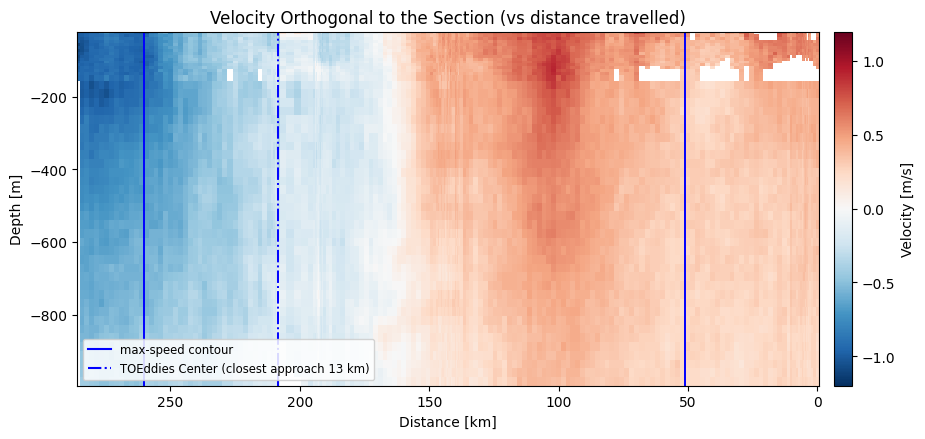

In [ ]:
# centre at every depth (shows any tilt); levels where the minimum hit the grid edge are hidden
x_dist = along_track_distance(sad["lon"], sad["lat"])      # same as Fig 1
vn = sad["u"] * en[0] + sad["v"] * en[1]                   # Fig 2's velocity, one column per fix
vn = fill_z_gaps(vn, sad["z"])                             # optional: close the OS150/OS38 seam

plot_adcp_section(sad, vn, x_dist/1000, "Velocity Orthogonal to the Section",
                  -1.2, 1.2, cmap="RdBu_r", cyc=cyc, eddy=edd,
                  eddy_center_nencioli=np.where(cen["edge"], np.nan, cen["x_fig1"]))

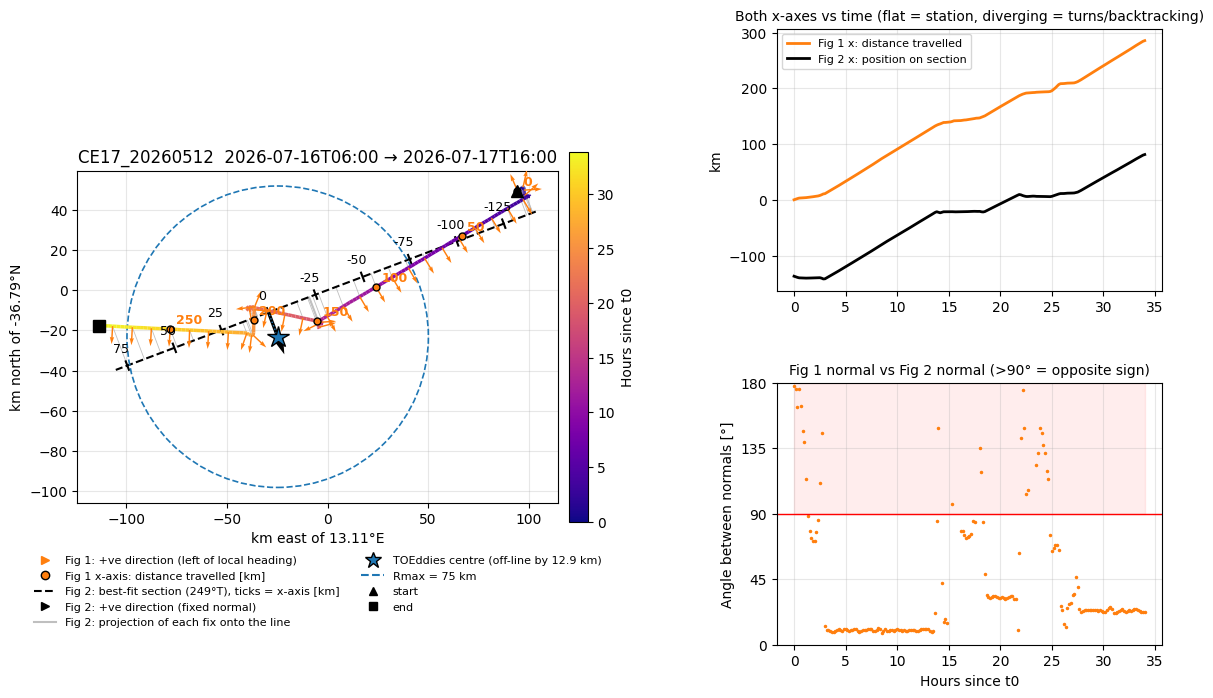

Distance travelled      :  285.4 km  (Fig 1 x-range)
Span along section line :  223.1 km  (Fig 2 x-range)
Section heading         :  249.3 °T
Centre offset from line :   12.9 km  (Fig 2 is NOT through the centre if this is large vs Rmax)
Fixes with no heading   : 14 / 205  (stations / creeping: blank columns in Fig 1)
Normals > 45° apart     : 28.3% of fixes
Normals > 90° apart     : 14.1% of fixes  (sign flipped in Fig 1 vs Fig 2)


In [49]:
# --- Map: what each of the two sections is plotted against ------------------------
# Fig 1 ("Velocity Perpendicular to Ship"):
#     x = cumulative distance travelled (x_dist), velocity on the LOCAL left-normal of the ship heading
# Fig 2 ("Velocity Orthogonal to the Section"):
#     x = projection on ONE straight best-fit line (s - s_c, 0 = TOEddies centre projected on the line),
#     velocity on ONE fixed normal `en`, averaged in DS_KM bins
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle

C1, C2 = "tab:orange", "k"           # Fig 1 elements / Fig 2 elements
t_hr = (sad["time"] - sad["time"][0]) / np.timedelta64(1, "h")

# local heading normal actually used for Fig 1 (same call as orthogonal_velocity)
az1 = np.deg2rad(track_heading(sad["lon"], sad["lat"], smooth_km=2.0))
nx1, ny1 = -np.cos(az1), np.sin(az1)               # left of the ship's local course
cosang = np.clip(nx1 * en[0] + ny1 * en[1], -1, 1)  # alignment with the Fig 2 normal
ang = np.degrees(np.arccos(cosang))

fig = plt.figure(figsize=(14, 8))
gs = GridSpec(2, 2, width_ratios=[1.5, 1], height_ratios=[1, 1], wspace=0.25, hspace=0.35)
ax = fig.add_subplot(gs[:, 0])
axb = fig.add_subplot(gs[0, 1])
axc = fig.add_subplot(gs[1, 1], sharex=axb)

# (a) map in the local tangent plane (km, true directions) ------------------------
ok = np.isfinite(xs) & np.isfinite(ys)
step = max(1, ok.sum() // 40)
idx = np.flatnonzero(ok)

# how each fix is folded onto the section line in Fig 2
for i in idx[::step]:
    px, py = origin + es * s[i]
    ax.plot([xs[i], px], [ys[i], py], color="0.75", lw=0.6, zorder=1)

pts = np.column_stack([xs, ys])[ok]
lc = LineCollection(np.stack([pts[:-1], pts[1:]], axis=1), cmap="plasma", lw=2.5, zorder=3)
lc.set_array(t_hr[ok][:-1])
ax.add_collection(lc)
cb = fig.colorbar(lc, ax=ax, shrink=0.6, pad=0.02)
cb.set_label("Hours since t0")

# Fig 1: local normals (direction of a POSITIVE value in Fig 1)
L = 0.04 * np.ptp(s)
qi = idx[::step]
ax.quiver(xs[qi], ys[qi], nx1[qi], ny1[qi], color=C1, angles="xy", scale_units="xy",
          scale=1 / L, width=0.003, zorder=4)

# Fig 1 x-axis: cumulative distance labels along the track
dk = x_dist / 1000
for d in np.arange(0, np.nanmax(dk), 50):
    i = np.nanargmin(np.abs(dk - d))
    ax.plot(xs[i], ys[i], "o", color=C1, ms=5, mec="k", zorder=5)
    ax.annotate(f"{d:.0f}", (xs[i], ys[i]), xytext=(4, 4), textcoords="offset points",
                color=C1, fontsize=9, fontweight="bold", zorder=6)

# Fig 2: the best-fit section line with its own x-axis ticks (0 = centre projection)
a, b = np.nanmin(s), np.nanmax(s)
ax.plot(*np.column_stack([origin + es * a, origin + es * b]), color=C2, ls="--", lw=1.5, zorder=2)
for xv in np.arange(np.ceil((a - s_c) / 25) * 25, b - s_c + 1e-6, 25):
    p = origin + es * (xv + s_c)
    e1, e2 = p - en * 0.01 * np.ptp(s), p + en * 0.01 * np.ptp(s)
    ax.plot([e1[0], e2[0]], [e1[1], e2[1]], color=C2, lw=1.5, zorder=2)
    q = p - en * 0.04 * np.ptp(s)
    ax.text(q[0], q[1], f"{xv:.0f}", color=C2, fontsize=9, ha="center", va="center", zorder=6)

# Fig 2: the single fixed normal (direction of a POSITIVE value in Fig 2)
pc = origin + es * s_c
ax.quiver(*pc, *en, color=C2, angles="xy", scale_units="xy", scale=1 / (2.5 * L),
          width=0.007, zorder=6)

# eddy: TOEddies centre, its projection on the line, and Rmax
ax.plot(cx, cy, "*", color=col, ms=16, mec="k", zorder=7)
ax.plot([cx, pc[0]], [cy, pc[1]], color=col, lw=1, ls=":", zorder=6)
if np.isfinite(rmax):
    ax.add_patch(Circle((cx, cy), rmax, fill=False, ec=col, ls="--", lw=1.2, zorder=2))
ax.plot(xs[idx[0]], ys[idx[0]], "^", color="k", ms=9, zorder=7)
ax.plot(xs[idx[-1]], ys[idx[-1]], "s", color="k", ms=8, zorder=7)

ax.set_aspect("equal")
ax.autoscale_view()
ax.set_xlabel(f"km east of {lon0:.2f}°E")
ax.set_ylabel(f"km north of {lat0:.2f}°N")
ax.set_title(f"{curr_eddy['name']}  {t0} → {t1}")
ax.grid(alpha=0.3)
handles = [
    mlines.Line2D([], [], color=C1, marker=">", ls="", label="Fig 1: +ve direction (left of local heading)"),
    mlines.Line2D([], [], color=C1, marker="o", mec="k", ls="", label="Fig 1 x-axis: distance travelled [km]"),
    mlines.Line2D([], [], color=C2, ls="--", label=f"Fig 2: best-fit section ({heading:.0f}°T), ticks = x-axis [km]"),
    mlines.Line2D([], [], color=C2, marker=">", ls="", label="Fig 2: +ve direction (fixed normal)"),
    mlines.Line2D([], [], color="0.75", label="Fig 2: projection of each fix onto the line"),
    mlines.Line2D([], [], color=col, marker="*", ls="", ms=12, mec="k", label=f"TOEddies centre (off-line by {d_c:.1f} km)"),
    mlines.Line2D([], [], color=col, ls="--", label=f"Rmax = {rmax:.0f} km"),
    mlines.Line2D([], [], color="k", marker="^", ls="", label="start"),
    mlines.Line2D([], [], color="k", marker="s", ls="", label="end"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8, frameon=False)

# (b) the two x-axes against time ------------------------------------------------
axb.plot(t_hr, dk, color=C1, lw=2, label="Fig 1 x: distance travelled")
axb.plot(t_hr, s - s_c, color=C2, lw=2, label="Fig 2 x: position on section")
axb.set_ylabel("km")
axb.set_title("Both x-axes vs time (flat = station, diverging = turns/backtracking)", fontsize=10)
axb.legend(fontsize=8)
axb.grid(alpha=0.3)

# (c) angle between the two normals --------------------------------------------
axc.plot(t_hr, ang, ".", color=C1, ms=3)
axc.axhline(90, color="r", lw=1)
axc.fill_between(t_hr, 90, 180, color="r", alpha=0.07)
axc.set_ylim(0, 180)
axc.set_yticks([0, 45, 90, 135, 180])
axc.set_xlabel("Hours since t0")
axc.set_ylabel("Angle between normals [°]")
axc.set_title("Fig 1 normal vs Fig 2 normal (>90° = opposite sign)", fontsize=10)
axc.grid(alpha=0.3)

fig.savefig(OUT_DIR / f"{curr_eddy['name']}_section_geometry.png", dpi=200, bbox_inches="tight")
plt.show()

good = np.isfinite(ang)
print(f"Distance travelled      : {np.nanmax(dk):6.1f} km  (Fig 1 x-range)")
print(f"Span along section line : {b - a:6.1f} km  (Fig 2 x-range)")
print(f"Section heading         : {heading:6.1f} °T")
print(f"Centre offset from line : {d_c:6.1f} km  (Fig 2 is NOT through the centre if this is large vs Rmax)")
print(f"Fixes with no heading   : {np.sum(~good)} / {len(ang)}  (stations / creeping: blank columns in Fig 1)")
print(f"Normals > 45° apart     : {np.mean(ang[good] > 45):5.1%} of fixes")
print(f"Normals > 90° apart     : {np.mean(ang[good] > 90):5.1%} of fixes  (sign flipped in Fig 1 vs Fig 2)")
